<a href="https://colab.research.google.com/github/Zaharaaz/Grape-Leaf-Disease-Detection/blob/main/PIIIII_V2_CBAM_(batch_16).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Mengecek ketersediaan GPU NVIDIA
!nvidia-smi

Wed Jun 18 14:00:53 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.54.15              Driver Version: 550.54.15      CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   46C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
# Untuk berinteraksi dengan os
import os
HOME = os.getcwd()
print(HOME)

/content


In [ ]:
# Menginstall library resmi YOLO
!pip install ultralytics
# Menginstall roboflow untuk akses dataset
!pip install roboflow

!pip install torch
!pip install torch torchvision
!pip install opencv-python
!pip install numpy
!pip install albumentations
!pip install wandb

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 28.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 102.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 88.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 57.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 11.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 9.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 63.9 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.5.82
    Uninstalling

In [ ]:
import torch
import torch.nn as nn
from ultralytics import YOLO
from ultralytics.nn.modules import C2f
import yaml
import os

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [ ]:
# API dataset
from roboflow import Roboflow
rf = Roboflow(api_key="nPSuIoLThZRBbgYyTNSc")
project = rf.workspace("tugas2zahara").project("grapes_leaf_disease")
version = project.version(4)
dataset = version.download("yolov12")


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to grapes_leaf_disease-4 in yolov12:: 100%|██████████| 3484/3484 [00:01<00:00, 2544.22it/s]


In [ ]:
# Memeriksa directory

test_dir = '/content/grapes_leaf_disease-4'

if not os.path.exists(test_dir):
    print(f"Directory not found: {test_dir}")
else:
    print(f"Directory found: {test_dir}")
    files_in_test_dir = os.listdir(test_dir)
    if not files_in_test_dir:
        print(f"Directory is empty: {test_dir}")
    else:
        print(f"Files in directory: {files_in_test_dir}")

Directory found: /content/grapes_leaf_disease-4
Files in directory: ['train', 'test', 'README.dataset.txt', 'data.yaml', 'README.roboflow.txt', 'valid']


In [ ]:
# CBAM
class ChannelAttention(nn.Module):
    def __init__(self, in_planes, ratio=16):
        super(ChannelAttention, self).__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)
        self.fc = nn.Sequential(
            nn.Conv2d(in_planes, in_planes // ratio, 1, bias=False),
            nn.ReLU(),
            nn.Conv2d(in_planes // ratio, in_planes, 1, bias=False)
        )
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_out = self.fc(self.avg_pool(x))
        max_out = self.fc(self.max_pool(x))
        out = avg_out + max_out
        return self.sigmoid(out)

class SpatialAttention(nn.Module):
    def __init__(self, kernel_size=7):
        super(SpatialAttention, self).__init__()
        self.conv1 = nn.Conv2d(2, 1, kernel_size, padding=kernel_size//2, bias=False)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_out = torch.mean(x, dim=1, keepdim=True)
        max_out, _ = torch.max(x, dim=1, keepdim=True)
        x = torch.cat([avg_out, max_out], dim=1)
        x = self.conv1(x)
        return self.sigmoid(x)

class CBAM(nn.Module):
    def __init__(self, in_planes, ratio=16, kernel_size=7):
        super(CBAM, self).__init__()
        self.ca = ChannelAttention(in_planes, ratio)
        self.sa = SpatialAttention(kernel_size)

    def forward(self, x):
        out = x * self.ca(x)
        result = out * self.sa(out)
        return result

# Modified C2f with CBAM
class C2f_CBAM(C2f):
    def __init__(self, c1, c2, n=1, shortcut=False, g=1, e=0.5):
        super().__init__(c1, c2, n, shortcut, g, e)
        self.cbam = CBAM(c2)

    def forward(self, x):
        # Original C2f forward pass
        y = list(self.cv1(x).chunk(2, 1))
        y.extend(m(y[-1]) for m in self.m)
        out = self.cv2(torch.cat(y, 1))

        # Apply CBAM
        return self.cbam(out)

def modify_yolo_with_cbam(model_path, num_classes=3):
    """
    Properly integrate CBAM into YOLOv12 architecture
    """
    # Load original model
    model = YOLO(model_path)

    # Access the model's architecture
    model_dict = model.model.state_dict()

    # Register CBAM modules
    def add_cbam_to_backbone(model):
        """Add CBAM modules to backbone layers"""
        for name, module in model.named_modules():
            if isinstance(module, C2f):
                # Replace C2f with C2f_CBAM
                parent_name = '.'.join(name.split('.')[:-1])
                module_name = name.split('.')[-1]

                parent_module = model
                for attr in parent_name.split('.'):
                    if attr:
                        parent_module = getattr(parent_module, attr)

                # Get original parameters
                c1 = module.cv1.conv.in_channels
                c2 = module.cv2.conv.out_channels
                n = len(module.m)

                # Replace with CBAM version
                cbam_module = C2f_CBAM(c1, c2, n)
                setattr(parent_module, module_name, cbam_module)

    # Apply CBAM to model
    add_cbam_to_backbone(model.model)

    return model

# Fixed Trainer Class
class YOLOv12CBAMTrainer:
    def __init__(self, model_size='s', dataset_path='/content/grapes_leaf_disease-4/data.yaml', device='cuda'):
        self.model_size = model_size
        self.dataset_path = dataset_path
        self.device = device if torch.cuda.is_available() else 'cpu'
        self.model = None
        self.num_classes = 3

    def setup_model(self):
        """Setup YOLOv12 model with CBAM"""
        # Load and modify model
        base_model_path = f'yolo12{self.model_size}.pt'
        self.model = modify_yolo_with_cbam(base_model_path, self.num_classes)

        print(f"YOLOv12{self.model_size} + CBAM model loaded successfully")
        print(f"Using device: {self.device}")
        print(f"Number of classes: {self.num_classes}")

        return self.model

    def verify_dataset_config(self):
        """Verify dataset configuration"""
        if not self.dataset_path:
            raise ValueError("Dataset path not provided")

        # Check data.yaml
        data_yaml = os.path.join(self.dataset_path, 'data.yaml')
        if not os.path.exists(data_yaml):
            raise ValueError(f"data.yaml not found at {data_yaml}")

        # Load and verify data.yaml
        with open(data_yaml, 'r') as f:
            data_config = yaml.safe_load(f)

        print(f"Dataset classes: {data_config.get('nc', 'Not found')}")
        print(f"Class names: {data_config.get('names', 'Not found')}")

        # Verify paths
        train_path = data_config.get('train', '')
        val_path = data_config.get('val', '')

        if not os.path.exists(train_path):
            print(f"Warning: Train path {train_path} not found")
        if not os.path.exists(val_path):
            print(f"Warning: Val path {val_path} not found")

        return data_yaml

    def train(self, epochs=100, imgsz=640, batch_size=8, lr0=0.01):
        """Train the model with proper configuration"""
        if not self.model:
            self.setup_model()

        # Verify dataset
        data_yaml = self.verify_dataset_config()

        # Training parameters
        train_args = {
            'data': data_yaml,
            'epochs': epochs,
            'imgsz': imgsz,
            'batch': batch_size,
            'lr0': lr0,
            'device': self.device,
            'project': 'plant_disease_yolov12_cbam',
            'name': f'train_{self.model_size}_cbam',
            'save': True,
            'cache': True,
            'patience': 0,
            'save_period': 10,  # Save every 10 epochs
            # Reduced augmentation for better stability
            'mixup': 0.0,
            'copy_paste': 0.0,
            'degrees': 5.0,
            'translate': 0.05,
            'scale': 0.3,
            'shear': 0.0,
            'perspective': 0.0,
            'flipud': 0.0,
            'fliplr': 0.5,
            'mosaic': 0.3,
            'hsv_h': 0.01,
            'hsv_s': 0.3,
            'hsv_v': 0.2
        }

        print("Starting training with configuration:")
        for key, value in train_args.items():
            print(f"  {key}: {value}")

        # Start training
        results = self.model.train(**train_args)
        return results

    def validate(self):
        """Validate the trained model"""
        if not self.model:
            raise ValueError("Model not initialized")

        data_yaml = self.verify_dataset_config()
        results = self.model.val(data=data_yaml)
        return results

    def predict(self, source, save=True, conf=0.25):
        """Make predictions"""
        if not self.model:
            raise ValueError("Model not initialized")

        results = self.model.predict(
            source=source,
            save=save,
            conf=conf,
            device=self.device
        )
        return results

# Usage example
def main():
    # Initialize trainer with correct configuration
    trainer = YOLOv12CBAMTrainer(
        model_size='s',
        dataset_path='/content/grapes_leaf_disease-4',
        device='cuda' if torch.cuda.is_available() else 'cpu'
    )

    # Setup model
    model = trainer.setup_model()

    # Verify dataset configuration
    trainer.verify_dataset_config()

    print("Ready to train!")
    print("Run: results = trainer.train()")

    return trainer

if __name__ == "__main__":
    trainer = main()


YOLOv12s + CBAM model loaded successfully
Using device: cuda
Number of classes: 3
Dataset classes: 3
Class names: ['black_rot', 'downey_mildew', 'healthy']
Ready to train!
Run: results = trainer.train()


In [ ]:
# Initialize trainer
trainer = YOLOv12CBAMTrainer(
    model_size='s',
    dataset_path='/content/grapes_leaf_disease-4',
    device='cuda'
)

# Setup and verify
model = trainer.setup_model()

# Train
results = trainer.train(
    epochs=150,
    imgsz=640,
# Batch 16
    batch_size=16,
# Learning rate
    lr0=0.0005
)

YOLOv12s + CBAM model loaded successfully
Using device: cuda
Number of classes: 3
Dataset classes: 3
Class names: ['black_rot', 'downey_mildew', 'healthy']
Starting training with configuration:
  data: /content/grapes_leaf_disease-4/data.yaml
  epochs: 150
  imgsz: 640
  batch: 16
  lr0: 0.0005
  device: cuda
  project: plant_disease_yolov12_cbam
  name: train_s_cbam
  save: True
  cache: True
  patience: 0
  save_period: 10
  mixup: 0.0
  copy_paste: 0.0
  degrees: 5.0
  translate: 0.05
  scale: 0.3
  shear: 0.0
  perspective: 0.0
  flipud: 0.0
  fliplr: 0.5
  mosaic: 0.3
  hsv_h: 0.01
  hsv_s: 0.3
  hsv_v: 0.2
Ultralytics 8.3.156 🚀 Python-3.11.13 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=True, cfg=None, classes=None, close_mosaic=10, cls=0.5, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/grapes_leaf_disease-4/data.yaml

train: Scanning /content/grapes_leaf_disease-4/train/labels.cache... 1533 images, 3 backgrounds, 0 corrupt: 100%|██████████| 1533/1533 [00:00<?, ?it/s]

WARNING ⚠️ cache='ram' may produce non-deterministic training results. Consider cache='disk' as a deterministic alternative if your disk space allows.



train: Caching images (1.8GB RAM): 100%|██████████| 1533/1533 [00:05<00:00, 289.25it/s]

albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, method='weighted_average', num_output_channels=3), CLAHE(p=0.01, clip_limit=(1.0, 4.0), tile_grid_size=(8, 8))


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 339.8±186.2 MB/s, size: 99.2 KB)


... (412 outputs left out)

    142/150      6.98G     0.7823     0.4576       1.21         30        640: 100%|██████████| 96/96 [00:41<00:00,  2.29it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 5/5 [00:01<00:00,  3.16it/s]

                   all        137        253      0.778      0.598      0.655      0.441



      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size


    143/150      6.98G     0.7357      0.444      1.184         39        640:  32%|███▏      | 31/96 [00:13<00:27,  2.34it/s]

In [ ]:
# Model validation
model.val(data='/content/grapes_leaf_disease-4/data.yaml')

Ultralytics 8.3.155 🚀 Python-3.11.13 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
YOLOv12s summary (fused): 159 layers, 9,232,041 parameters, 0 gradients, 21.2 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 87.3±167.0 MB/s, size: 42.2 KB)


val: Scanning /content/grape_leaf_disease_v2-1/valid/labels.cache... 80 images, 4 backgrounds, 0 corrupt: 100%|██████████| 80/80 [00:00<?, ?it/s]

WARNING ⚠️ cache='ram' may produce non-deterministic training results. Consider cache='disk' as a deterministic alternative if your disk space allows.



val: Caching images (0.1GB RAM): 100%|██████████| 80/80 [00:00<00:00, 292.12it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 10/10 [00:02<00:00,  4.56it/s]


                   all         80        198      0.584      0.401      0.428      0.285
             black_rot          7         74      0.108     0.0541     0.0388     0.0138
         downey_mildew         20         70      0.756      0.243      0.322      0.136
               healthy         49         54      0.887      0.907      0.925      0.707
Speed: 4.4ms preprocess, 13.8ms inference, 0.0ms loss, 1.5ms postprocess per image
Results saved to plant_disease_yolov12_cbam/train_s_cbam2


ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7998c49a71d0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04

In [ ]:
#
train: '/content/grape_leaf_disease_v2-1/train/images'
val: '/content/grape_leaf_disease_v2-1/valid'
test: '/content/grape_leaf_disease_v2-1/test/images'

# Number of classes
nc: 3

# Class names
names: ['healthy', 'black_rot', 'downy_mildew']


image 1/41 /content/grape_leaf_disease_v2-1/test/images/Black_Rot_0033_png.rf.8fd5adf4d853ad2789103e5848b13623.jpg: 640x640 3 black_rots, 20.9ms
image 2/41 /content/grape_leaf_disease_v2-1/test/images/Black_Rot_0037_png.rf.7ff40d5ecf5bde74aa175dcbd104b9b7.jpg: 640x640 (no detections), 20.9ms
image 3/41 /content/grape_leaf_disease_v2-1/test/images/Black_Rot_0584_png.rf.57475ca4c3dbc86f0f13611d20cc9037.jpg: 640x640 14 black_rots, 3 downey_mildews, 20.9ms
image 4/41 /content/grape_leaf_disease_v2-1/test/images/Downy_Mildew_0017_png.rf.e6bb9e40ccefe6d5b790f1340c74cc54.jpg: 640x640 (no detections), 20.9ms
image 5/41 /content/grape_leaf_disease_v2-1/test/images/Healthy_Leaves_0284_png.rf.8e9a3e0270b8bb9844b22c42773c7240.jpg: 640x640 1 healthy, 20.9ms
image 6/41 /content/grape_leaf_disease_v2-1/test/images/Healthy_Leaves_0291_png.rf.c1243e7098181d4445967d262a229048.jpg: 640x640 1 healthy, 20.9ms
image 7/41 /content/grape_leaf_disease_v2-1/test/images/Healthy_Leaves_0611_png.rf.358df4aeceaeb0

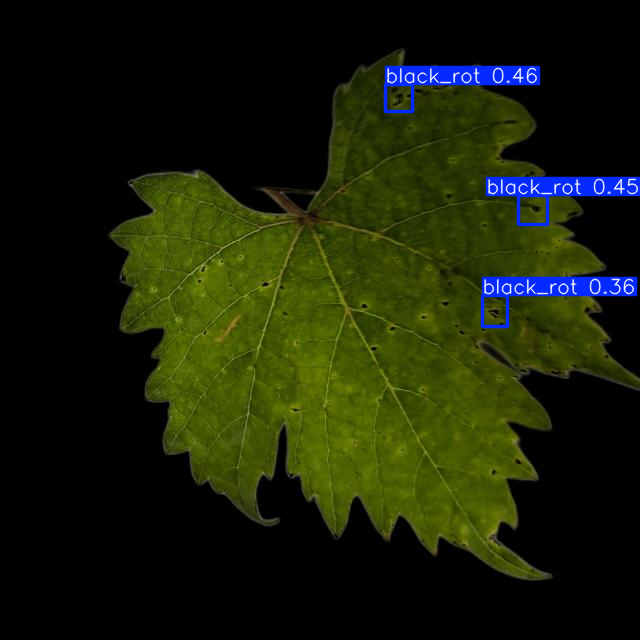

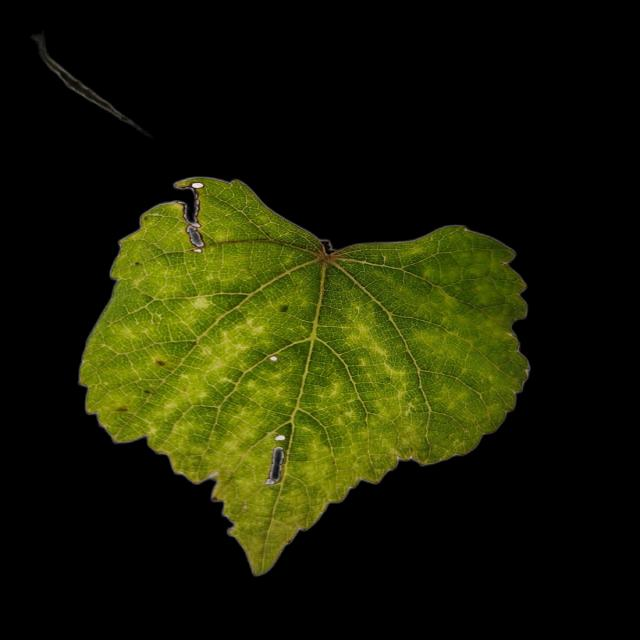

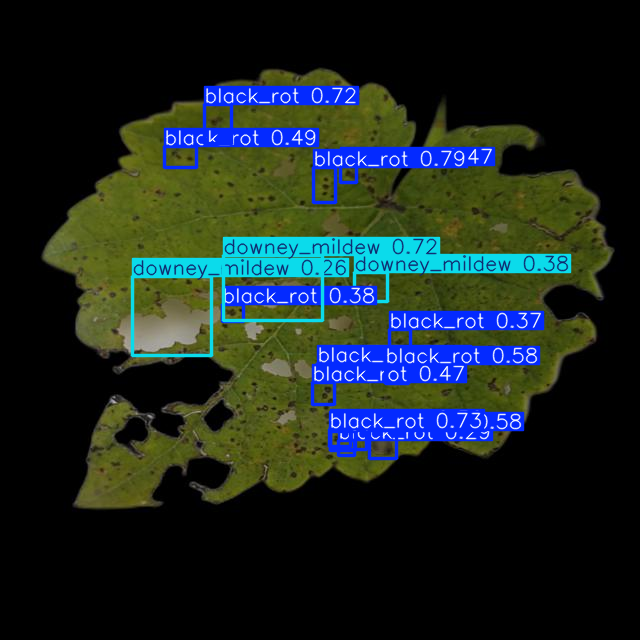

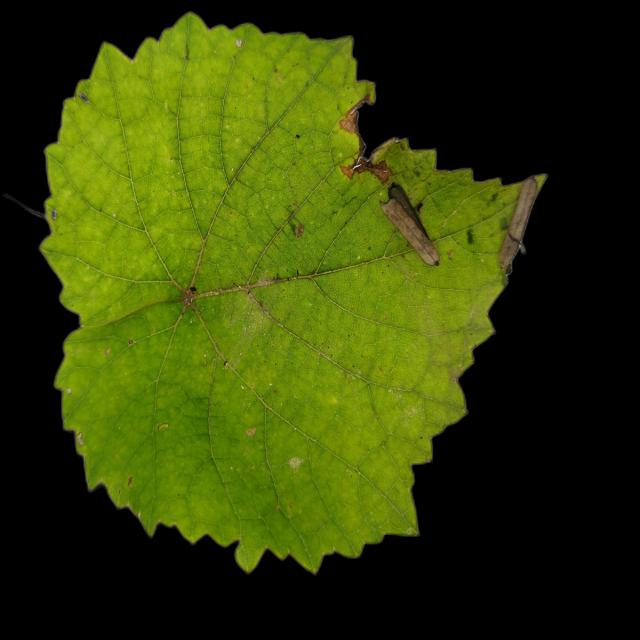

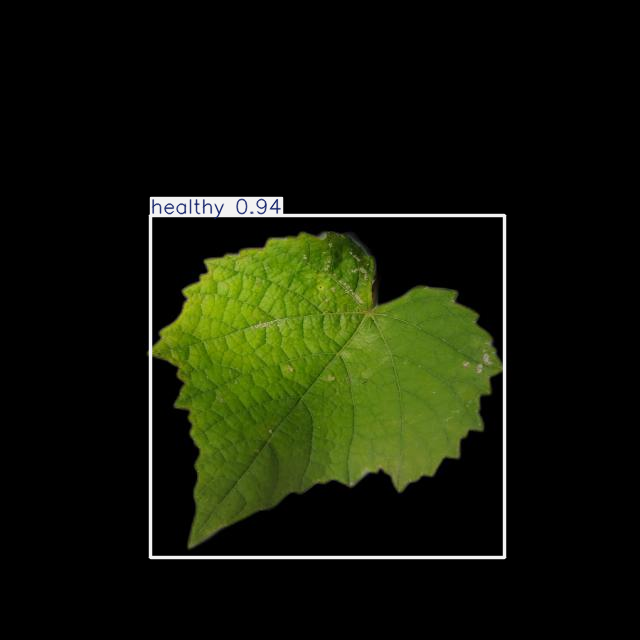

...

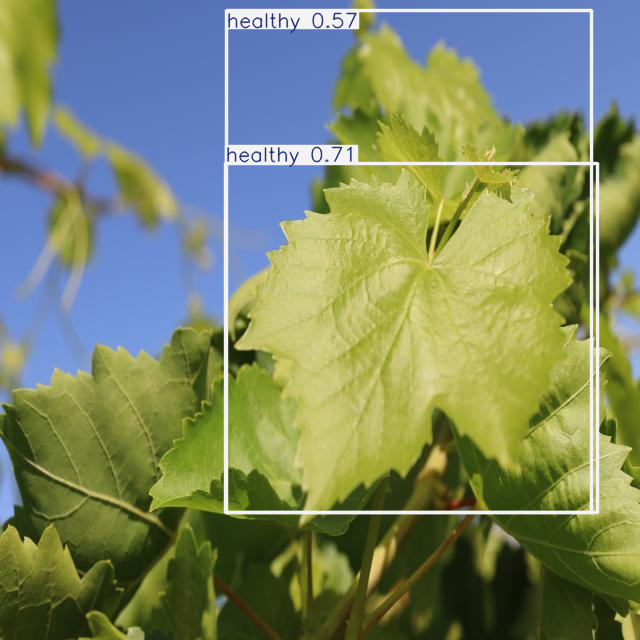

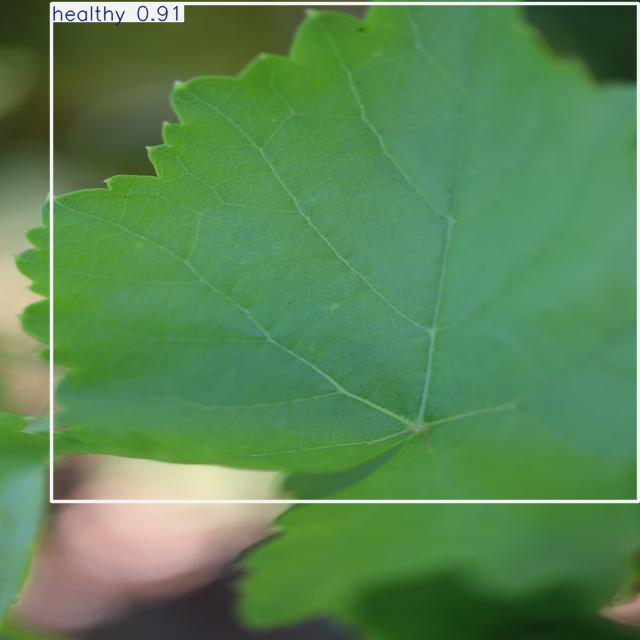

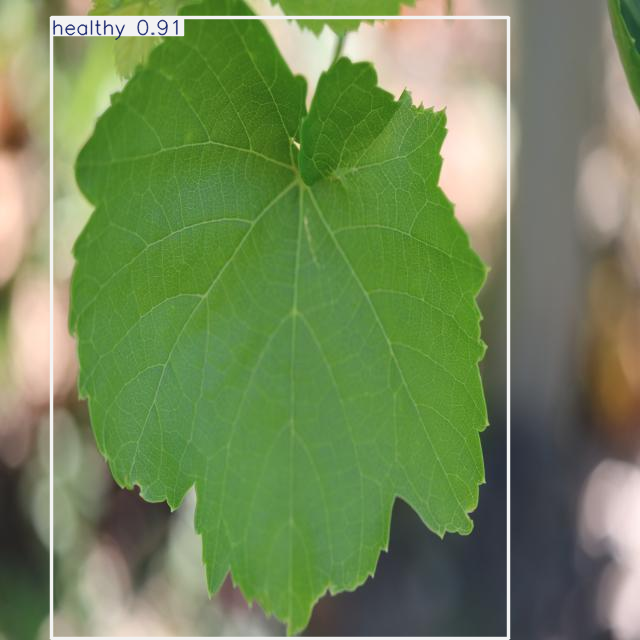

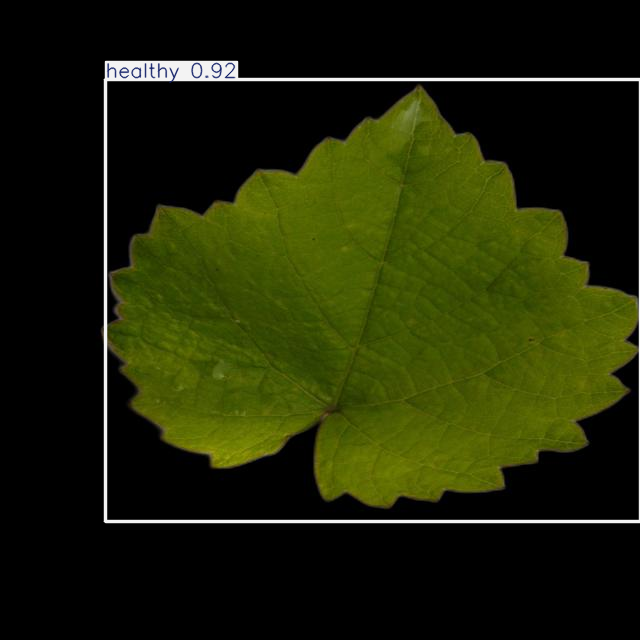

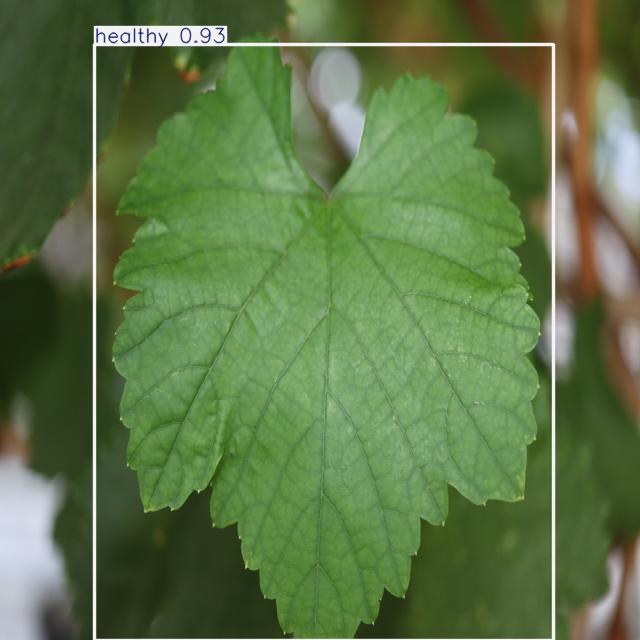

In [ ]:
# Inference in test image
results = model('/content/grape_leaf_disease_v2-1/test/images')

# Show results with bounding box
for result in results:
    result.show()

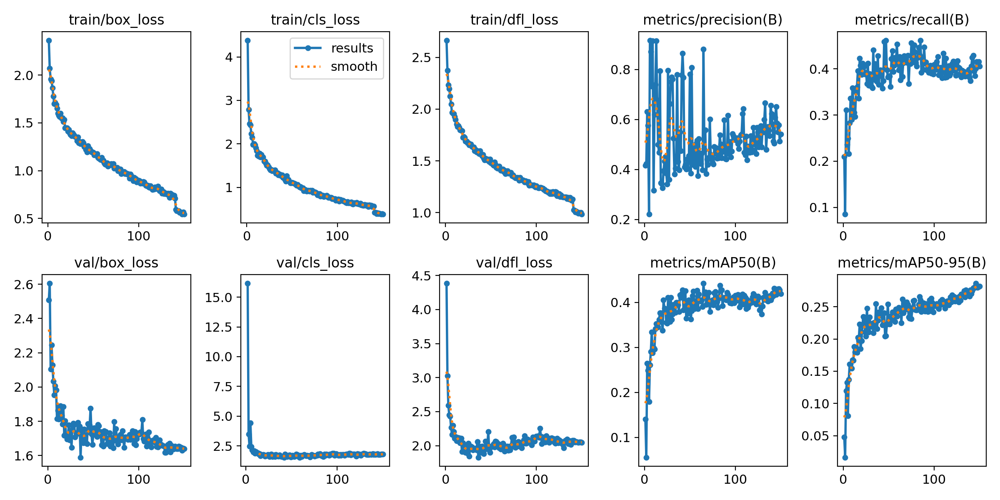

In [ ]:
from IPython.display import Image

#Result
Image(filename=f'/content/plant_disease_yolov12_cbam/train_s_cbam/results.png', width=600)

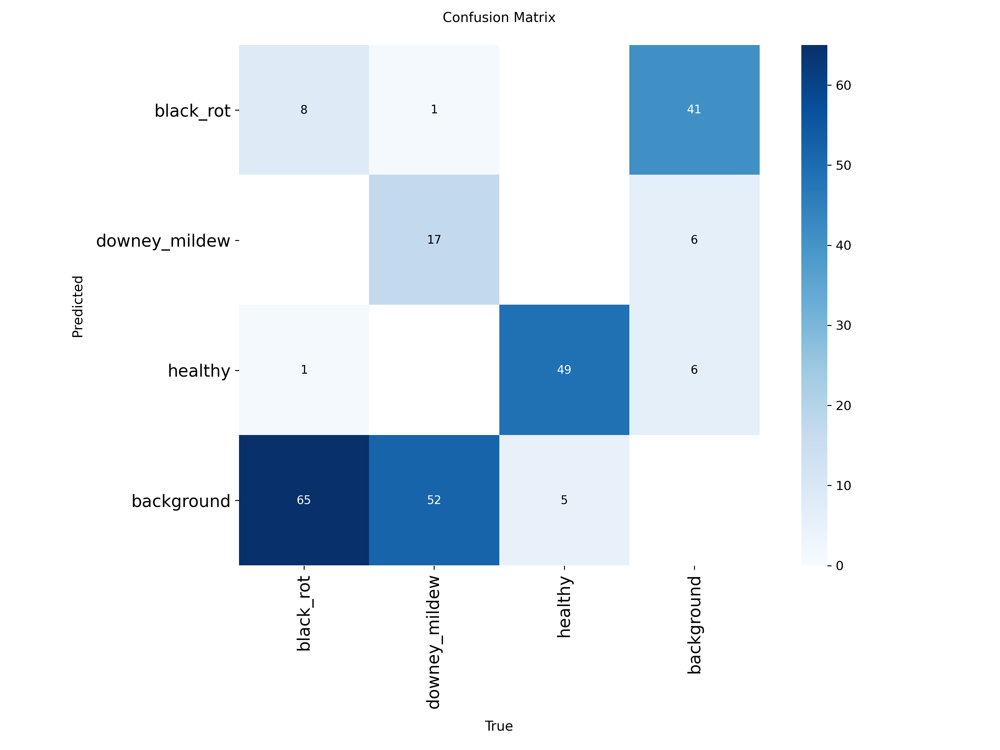

In [ ]:
# Confusion Matrix
Image(filename=f'/content/plant_disease_yolov12_cbam/train_s_cbam/confusion_matrix.png', width=600)

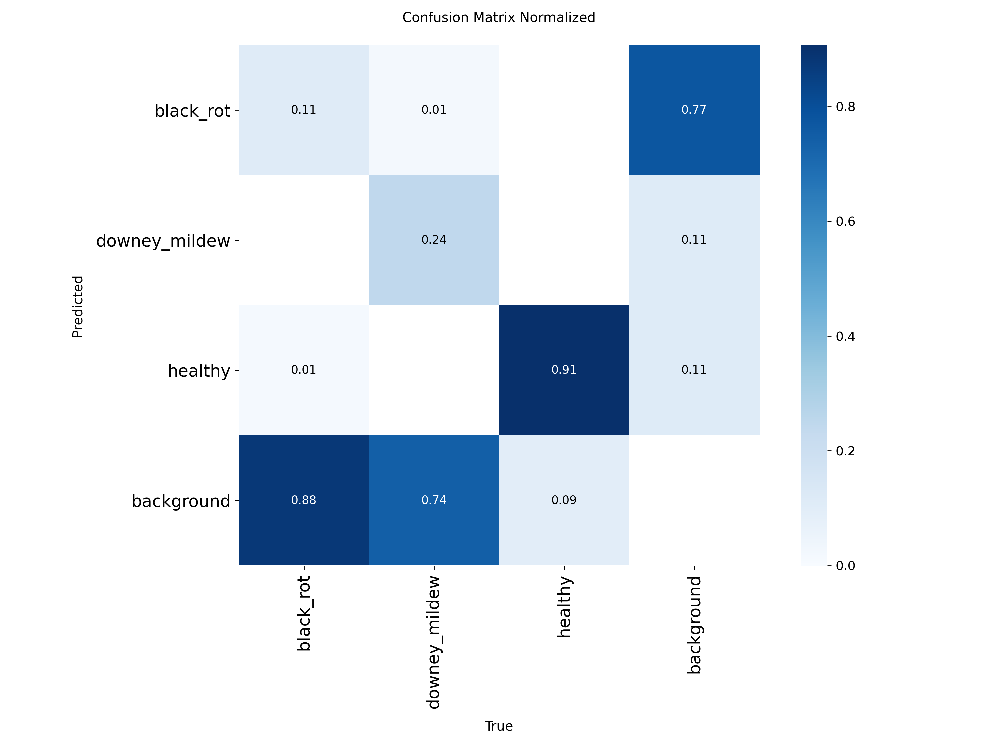

In [ ]:
# Confusion Matrix Normalized
Image(filename=f'/content/plant_disease_yolov12_cbam/train_s_cbam/confusion_matrix_normalized.png', width=600)

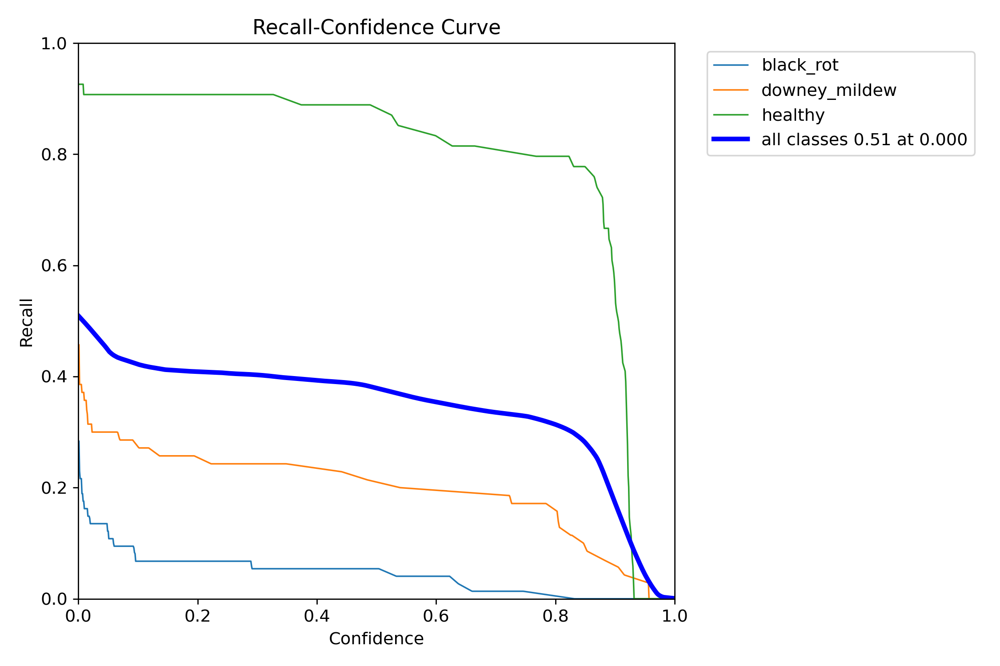

In [ ]:
# Recall
Image(filename=f'/content/plant_disease_yolov12_cbam/train_s_cbam/R_curve.png', width=600)

In [ ]:
# F1
Image(filename=f'/content/plant_disease_yolov12_cbam/train_s_cbam/F1_curve.png', width=600)

In [ ]:
# Precission Recall
Image(filename=f'/content/plant_disease_yolov12_cbam/train_s_cbam/PR_curve.png', width=600)